# Bunker Mini: Planning During Navigation

Verify that the C++ GP/GRG planner runs while Bunker Mini navigates in Gazebo/Nav2, that 1 Hz continuous temperature acquisition remains complete, and that candidates are handed over at the correct endpoint with an updated GP and actual timestamps. This is one scheduling/performance verification, not a comparison of scoring policies or real-field accuracy.

Recorded run: run_20261112T001310Z.

## Configuration and execution

| Item | Setting |
| --- | --- |
| Scene / robot | Flat 97 x 64 m rectangle, boundary walls, no interior obstacles; Bunker Mini, Gazebo, ROS 2 Jazzy and Nav2 |
| Localization / mapping | Ideal simulator localization; planar translation of real observations, not surveyed map registration |
| Candidates / start | 30 rounded 6 x 5 checkpoints plus start (48.5,32) m; 930 directed Nav2 paths |
| Mission / sensing | 300 s including initial planning; 1 Hz ticks 1-299, no dwell; free endpoint, no mandatory return |
| Initial GP | 980 real observations; fixed ARD RBF, no retraining |
| RBF lengths | x=3.598 m, y=21.094 m, t=21.136 s; all parameters in initial.json |
| Synthetic source | Independent GSTools finite-mode Matern SRF; nu=1.5, 1024 modes, seed=20261109 |
| Field scales / noise | [12, 12, 180] (m,m,s); noise SD 0.03 degC, keyed by measurement ID |
| Field reference resolution | 0.1 m / 0.5 s; arbitrary-position/time queries, no precomputed space-time grid |
| Scoring | Adaptive WIVR; 70 area-clipped 10 m cells x 151 target times at 2 s = 10,570 targets; route events remain 1 Hz |
| GRG / guards | Depth 2, two time splits; 45 s search and 10 s selected-route re-score guards |
| Parallelism | OpenMP/Eigen, 4 matrix threads; event-feature batches of 32 |
| Navigation | RPP, velocity smoother and bounded watchdog; forward/nominal 1.0 m/s, reverse 0.3 m/s, yaw command cap 0.6 rad/s |
| Update | Frozen committed GP during lookahead; actual samples buffered and assimilated at activation |
| Evaluation | 70 fixed locations at 0/75/150/225/300 s; GP committed by each time; History-Only baseline |

Initial search -> actual-data activation -> Nav2 goal. During that goal, LookaheadManager::ask_search requests a candidate anchored at the endpoint and a predicted arrival time. Planner::plan freezes the committed GP and weights; current-leg samples stay buffered. At actual arrival, activate_candidate waits for a candidate if necessary, commits the actual batch, and re-scores/trims the route at actual time before dispatch. Replanning never preempts the active Nav2 goal. At 300 s, sensing/navigation stop; an outstanding calculation may finish without dispatch.

## Recorded results

| Measurement | Recorded value |
| --- | --- |
| Simulation / wall time | 300.046 / 300.052 s |
| Received / missing / duplicate measurements | 299 / 0 / 0 |
| Completed navigation segments | 3 |
| Nonempty GP updates | 4; 3 after initial activation |
| Lookahead searches / arrival activations | 4 / 4 |
| Lookahead planning during physical motion | 93.30 s |
| Checkpoint handover waits | 2.42, 1.54, 1.29 s |
| Initial dispatch wait | 46.89 s |
| Total computation / computation while stationary | 145.22 / 51.40 s |
| Search guard timeouts | 3 |
| Real-time factor | 0.99998 |
| Distance travelled | 220.51 m |
| Sampled summed-process RSS / container peak | 2048 / 2533 MiB |
| SRF / sensor round-trip P95 | 1.124 / 3.262 ms |
| Committed new / terminal pending observations | 252 / 47 |
| End-time synthetic RMSE / History-Only | 0.195787 / 0.196260 degC |
| Maximum C++ / Python score discrepancy | 8.2e-17 |
| Movement-time planning / full-search acceptance | True / False |

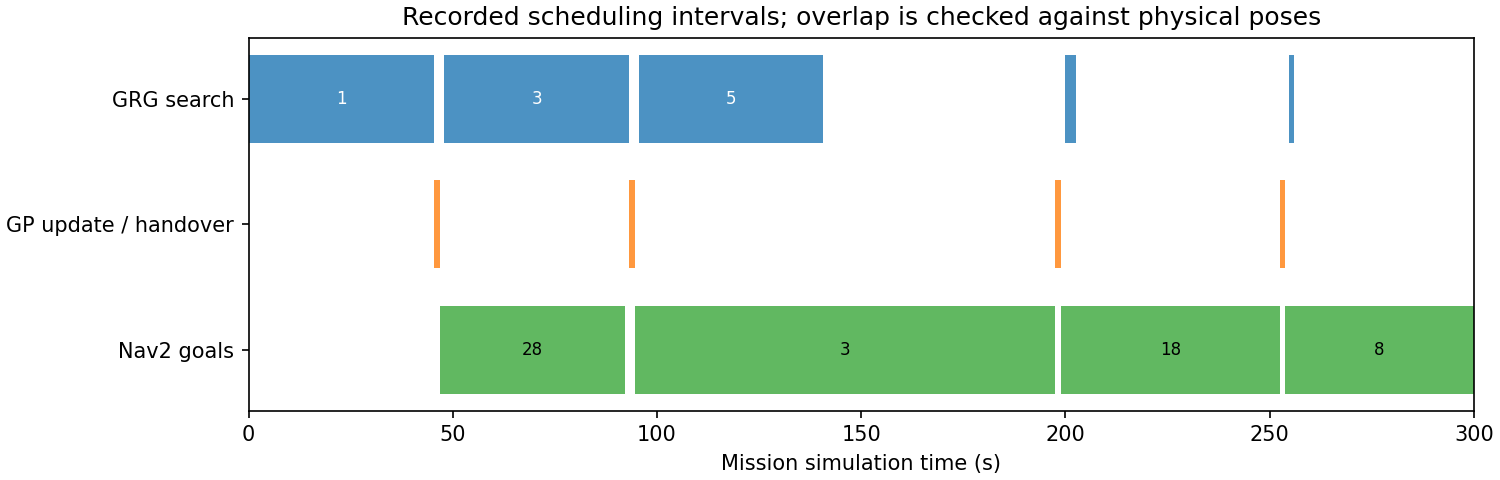

Arrival estimate errors: [{'goal_epoch': 1, 'forecast_s': 104.736708736, 'actual_s': 92.09599999999999, 'error_s': -12.640708736000008}, {'goal_epoch': 2, 'forecast_s': 184.3979984741211, 'actual_s': 197.41400000000002, 'error_s': 13.01600152587892}, {'goal_epoch': 3, 'forecast_s': 264.932071204, 'actual_s': 252.47800000000004, 'error_s': -12.454071203999973}]


In [1]:
from pathlib import Path
import json
from IPython.display import display,Image,Video
ROOT=Path.cwd()
RUN=ROOT/"result"/'run_20261112T001310Z'
m=json.loads((RUN/"metrics.json").read_text())
a=json.loads((RUN/"audit_and_estimation.json").read_text())
display(Image(filename=str(RUN/"scheduling_timeline.png")))
print("Arrival estimate errors:",m["arrival_forecast_errors_s"])

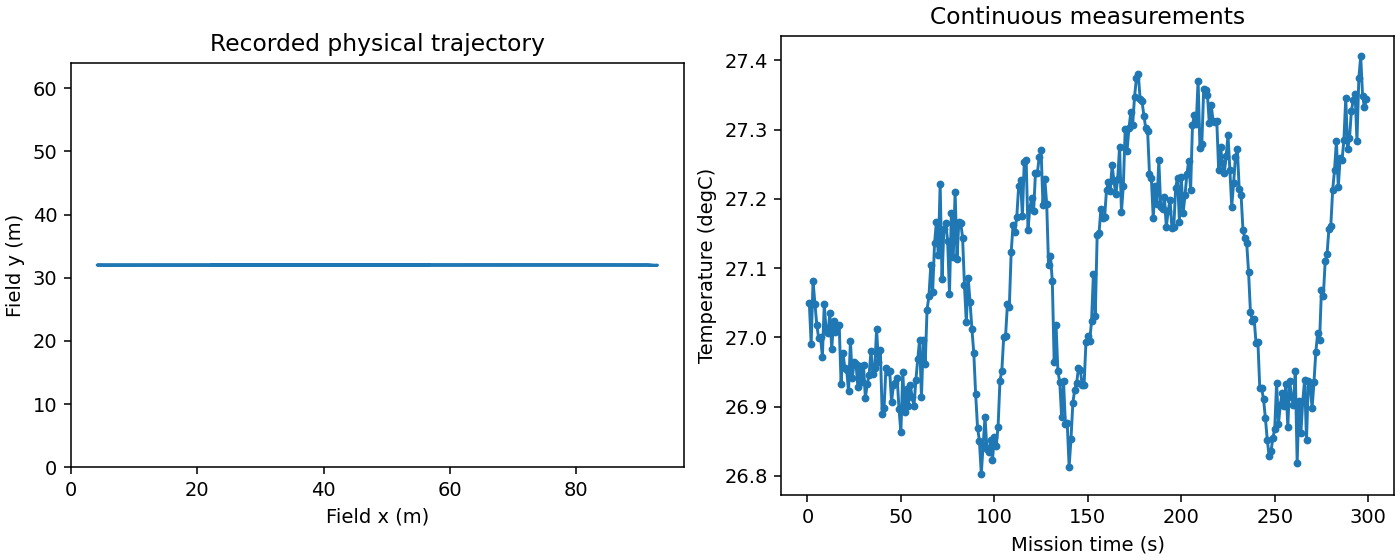

In [2]:
display(Image(filename=str(RUN/"trajectory_temperature.png")))
display(Video(str(RUN/"robot_replay.mp4"),embed=True,width=900))

## GP updates and independent verification

Lookahead freezes the committed GP; current-leg samples stay buffered until activation. Independent Python calculations check the C++ GP and route scores.

In [3]:
plans=sorted((json.loads(p.read_text()) for p in RUN.glob("plan_*.json")),key=lambda p:p["round"])
for p in plans:
 print({k:p[k] for k in ["round","kind","lookahead","anchor","batch_size","gp_version","planning_started_t","t","finish_t","route","timeout"]})
print("GP:",a["gp_checks"])
print("Frozen state:",a["lookahead_checks"])
print("Maximum score error:",max(r["absolute_error"] for r in a["returned_route_score_checks"]))

{'round': 1, 'kind': 'search', 'lookahead': False, 'anchor': 0, 'batch_size': 0, 'gp_version': 0, 'planning_started_t': 0.004000000000001336, 't': 0.015999999999998238, 'finish_t': 45.352000000000004, 'route': [0, 28, 3, 28], 'timeout': True}
{'round': 2, 'kind': 'activate', 'lookahead': False, 'anchor': 0, 'batch_size': 45, 'gp_version': 1, 'planning_started_t': 45.388000000000005, 't': 45.434, 'finish_t': 46.882000000000005, 'route': [0, 28, 3, 28], 'timeout': False}
{'round': 3, 'kind': 'search', 'lookahead': True, 'anchor': 28, 'batch_size': 0, 'gp_version': 1, 'planning_started_t': 47.902, 't': 104.736708736, 'finish_t': 93.13, 'route': [28, 3, 0, 28], 'timeout': True}
{'round': 4, 'kind': 'activate', 'lookahead': False, 'anchor': 28, 'batch_size': 48, 'gp_version': 2, 'planning_started_t': 93.16799999999999, 't': 93.21, 'finish_t': 94.506, 'route': [28, 3, 0, 28], 'timeout': False}
{'round': 5, 'kind': 'search', 'lookahead': True, 'anchor': 3, 'batch_size': 0, 'gp_version': 2, 'p

## Synthetic reconstruction

70 fixed locations at 0/75/150/225/300 s; only the GP already committed at each time is evaluated. History-Only uses the same inputs and truth. Terminal data are not artificially assimilated.

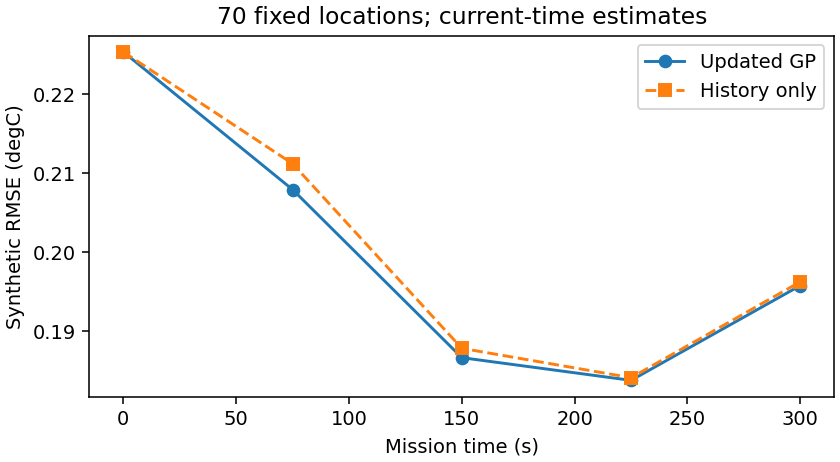

{'time_s': 0.0, 'rmse_c': 0.22535984386319444, 'history_only_rmse_c': 0.22535984386319444, 'observations': 980}
{'time_s': 75.0, 'rmse_c': 0.20793539203004716, 'history_only_rmse_c': 0.21120950613218337, 'observations': 1025}
{'time_s': 150.0, 'rmse_c': 0.186653765322967, 'history_only_rmse_c': 0.18783475792073165, 'observations': 1073}
{'time_s': 225.0, 'rmse_c': 0.183781476703092, 'history_only_rmse_c': 0.18411737955679627, 'observations': 1177}
{'time_s': 300.0, 'rmse_c': 0.19578718346282764, 'history_only_rmse_c': 0.19625998084924437, 'observations': 1232}


In [4]:
display(Image(filename=str(RUN/"estimation.png")))
for row in a["evaluation"]:
 print({k:row[k] for k in ["time_s","rmse_c","history_only_rmse_c","observations"]})

## Conclusion and limits

Movement-time planning is verified; strict combined acceptance remains false because 3 searches hit the 45 s guard. Initial planning still waits 46.89 s. Activation checks an existing candidate under the updated GP, without repeating full route selection. ETA errors and late plans can still create waiting.

The trace remains effectively collinear (y-span 0.109 m); area coverage is not established. Synthetic field scales, sensor response and surveyed map registration remain unvalidated.

47 terminal observations remain saved but uncommitted. RMSE uses the committed GP against synthetic truth, without an artificial terminal update; it is not real-field accuracy or policy superiority. Expected endpoint navigation cancellations: 1.

Raw truth-twist yaw outliers: 4; per-run quaternion/pose checks are retained in yaw_incident.json, with no raw data removed. No GUI frame rate was measured; real-time factor and sensing ticks are reported separately.

### Route geometry and kernel validation

The nearly collinear route is an observed planner outcome, not evidence by itself of a navigation failure or insufficient training data. The fitted ARD RBF lengths are 3.598 m along x, 21.094 m along y and 21.136 s in time. At the same time, a 5 m separation has prior correlation approximately 0.381 along x and 0.972 along y. This directional correlation makes horizontal exploration less redundant under the current model and contributes to its WIVR score advantage. Candidate geometry, route timing, scoring quadrature and incomplete search also affect the chosen route. Additional independent runs with better directional coverage, repeated locations and different times would help validate and refit the parameters. More data do not guarantee a turning route; held-out reconstruction error should assess model adequacy rather than route appearance. The fitted anisotropy is not independently established as a physical-field property.

### Search truncation and computation

This run executed 5 GRG searches, including the initial search and 4 moving lookahead searches; 3 hit the 45 s wall guard. Activation re-scores are separate from full searches. Thirty candidates, at least 980 GP observations, 1 Hz hypothetical route events and 10,570 evaluation targets require repeated dense covariance and matrix calculations. Exceeding the guard reflects the workload, implementation efficiency and chosen time limit; it does not by itself invalidate the GP/GRG formulation. The guard returns the best fully evaluated route found so far. Movement-time planning reduces stationary waiting but does not remove the computation or the search limit.

### How the kernel influences navigation

Kernel correlation -> GP posterior uncertainty -> expected joint benefit of along-route observations -> WIVR route score -> GRG route selection -> Nav2 execution. The kernel defines how a measurement informs other positions and times; it does not directly issue steering commands. WIVR estimates weighted uncertainty reduction, not realized reconstruction error. Kernel hyperparameters stay fixed online in this experiment. New temperature values update the posterior mean, while measurement locations and times determine the posterior covariance for a fixed kernel and noise model. Updating the GP posterior is therefore distinct from refitting kernel hyperparameters; the robot does not automatically relearn its spatial length scales while moving.